# 04 Model: can we predict a movie's rating?

Target: `rating`. Features: only things known before release.
Train on films before 2015, test on 2015 onwards.

- **Reads:** data/processed/movies.parquet
- **Writes:** nothing (06_export retrains and saves the final model)
- **Run after:** 02_clean_join

What I found: a random forest beats always guessing the average by 24% (test MAE 0.728 vs 0.961).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

movies = pd.read_parquet("../data/processed/movies.parquet")
print(movies.shape)

(49453, 34)


In [2]:
movies = movies.sort_values(["year", "tconst"]).reset_index(drop=True)

by_director = movies.groupby("director_id")["rating"]
movies["dir_prev_films"] = by_director.cumcount()
movies["dir_prev_avg"] = by_director.transform(lambda s: s.shift(1).expanding().mean())

movies.loc[movies["director"] == "Christopher Nolan",
           ["year", "title", "rating", "dir_prev_films", "dir_prev_avg"]].round(2)

,year,title,rating,dir_prev_films,dir_prev_avg
15587,1998,Following,7.4,0.0,NaN
16536,2000,Memento,8.4,1.0,7.40
17704,2002,Insomnia,7.2,2.0,7.90
19865,2005,Batman Begins,8.2,3.0,7.67
21217,2006,The Prestige,8.5,4.0,7.80
22724,2008,The Dark Knight,9.1,5.0,7.94
25163,2010,Inception,8.8,6.0,8.13
27153,2012,The Dark Knight Rises,8.4,7.0,8.23
29718,2014,Interstellar,8.7,8.0,8.25
34700,2017,Dunkirk,7.8,9.0,8.30


In [3]:
print(movies["dir_prev_avg"].isna().sum(), "movies have no director history")
print(movies["dir_prev_avg"].isna().mean().round(3))

20537 movies have no director history
0.415


In [4]:
SPLIT_YEAR = 2015
train = movies[movies["year"] < SPLIT_YEAR].copy()
test = movies[movies["year"] >= SPLIT_YEAR].copy()

print("train:", train.shape, "years", train["year"].min(), "to", train["year"].max())
print("test: ", test.shape, "years", test["year"].min(), "to", test["year"].max())
print("mean rating  train:", round(train["rating"].mean(), 2), " test:", round(test["rating"].mean(), 2))

train: (31181, 36) years 1906 to 2014
test:  (18272, 36) years 2015 to 2026
mean rating  train: 6.32  test: 6.08


In [5]:
genre_cols = [c for c in movies.columns if c.startswith("g_")]

runtime_fill = train["runtime"].median()
dir_fill = train["rating"].mean()

def make_features(df):
    X = pd.DataFrame(index=df.index)
    X["year"] = df["year"].astype(float)
    X["runtime"] = df["runtime"].astype(float).fillna(runtime_fill)
    X["dir_prev_films"] = df["dir_prev_films"].fillna(0)
    X["dir_prev_avg"] = df["dir_prev_avg"].fillna(dir_fill)
    X["has_dir_history"] = df["dir_prev_avg"].notna().astype(int)
    X[genre_cols] = df[genre_cols]
    return X

X_train = make_features(train)
X_test = make_features(test)
y_train = train["rating"]
y_test = test["rating"]

print(X_train.shape, X_test.shape)
print("missing values left:", X_train.isna().sum().sum(), X_test.isna().sum().sum())
print("runtime fill:", runtime_fill, " director fill:", round(dir_fill, 2))

(31181, 29) (18272, 29)
missing values left: 0 0
runtime fill: 99.0  director fill: 6.32


In [6]:
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
print("Baseline MAE:", round(baseline_mae, 3))

Baseline MAE: 0.961


In [7]:
lin = LinearRegression()
lin.fit(X_train, y_train)

lin_train_mae = mean_absolute_error(y_train, lin.predict(X_train))
lin_test_mae = mean_absolute_error(y_test, lin.predict(X_test))
print("Linear  train MAE:", round(lin_train_mae, 3), " test MAE:", round(lin_test_mae, 3))

Linear  train MAE: 0.655  test MAE: 0.755


In [8]:
coefs = pd.Series(lin.coef_, index=X_train.columns).sort_values()
coefs.round(3)

g_Horror          -0.584
g_Sci-Fi          -0.275
g_Action          -0.228
g_Western         -0.178
g_Adventure       -0.128
g_Family          -0.096
g_Fantasy         -0.095
g_Musical         -0.082
g_Film-Noir       -0.079
g_Romance         -0.070
g_Thriller        -0.049
g_Sport           -0.038
g_Comedy          -0.016
dir_prev_films    -0.010
year              -0.009
g_Talk-Show        0.000
g_History          0.000
runtime            0.009
g_Music            0.018
g_Crime            0.049
has_dir_history    0.051
g_War              0.056
g_Mystery          0.070
g_Biography        0.158
g_Drama            0.342
g_News             0.406
dir_prev_avg       0.505
g_Animation        0.766
g_Documentary      1.126
dtype: float64

In [9]:
rf_deep = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_deep.fit(X_train, y_train)

print("Deep forest  train MAE:", round(mean_absolute_error(y_train, rf_deep.predict(X_train)), 3),
      " test MAE:", round(mean_absolute_error(y_test, rf_deep.predict(X_test)), 3))

Deep forest  train MAE: 0.252  test MAE: 0.768


In [10]:
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_train_mae = mean_absolute_error(y_train, rf.predict(X_train))
rf_test_mae = mean_absolute_error(y_test, rf.predict(X_test))
print("Forest  train MAE:", round(rf_train_mae, 3), " test MAE:", round(rf_test_mae, 3))

Forest  train MAE: 0.578  test MAE: 0.728


In [11]:
results = pd.DataFrame({
    "model": ["Baseline (average)", "Linear regression", "Random forest"],
    "train_MAE": [mean_absolute_error(y_train, np.full(len(y_train), y_train.mean())),
                  lin_train_mae, rf_train_mae],
    "test_MAE": [baseline_mae, lin_test_mae, rf_test_mae],
})
results["better_than_baseline"] = 1 - results["test_MAE"] / baseline_mae
results.round(3)

,model,train_MAE,test_MAE,better_than_baseline
0,Baseline (average),0.859,0.961,0.000
1,Linear regression,0.655,0.755,0.214
2,Random forest,0.578,0.728,0.243


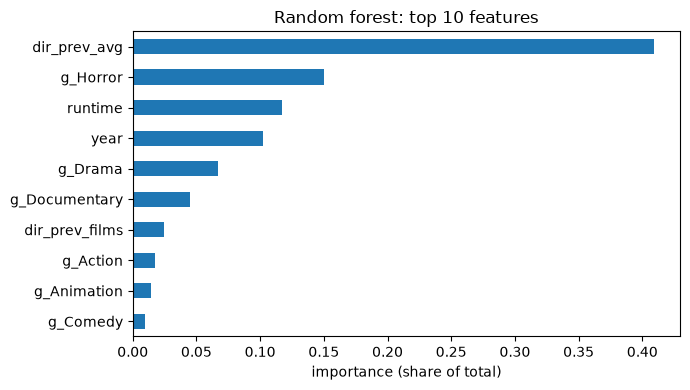

In [12]:
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importance.tail(10).plot(kind="barh", figsize=(7, 4), title="Random forest: top 10 features")
plt.xlabel("importance (share of total)")
plt.tight_layout()
plt.show()

In [13]:
test["predicted"] = rf.predict(X_test)
test["abs_error"] = (test["rating"] - test["predicted"]).abs()

test.groupby(X_test["has_dir_history"])["abs_error"].agg(["mean", "count"]).round(3)

,mean,count
has_dir_history,,
0,0.816,8503
1,0.651,9769


In [14]:
test.sort_values("abs_error", ascending=False)[
    ["title", "year", "director", "rating", "predicted"]
].head(8).round(2)

,title,year,director,rating,predicted
43707,Melania,2022,Jurij Gruden,1.1,7.08
46811,We Love Bad Boys,2024,Raju Rajendra Prasad,1.2,6.81
40040,321 Action,2020,Shady Al Ramly,1.0,6.59
48978,Melania,2026,Brett Ratner,1.6,7.09
34148,Smolensk,2016,Antoni Krauze,1.2,6.65
40320,Sadak 2,2020,Mahesh Bhatt,1.2,6.65
45354,The Witness,2023,David Dadunashvili,1.6,6.94
37367,The Trump Prophecy,2018,Stephan Schultze,1.6,6.94


In [15]:
famous = ["Oppenheimer", "Dune: Part Two", "Tenet", "Barbie", "Everything Everywhere All at Once"]
test.loc[test["title"].isin(famous), ["title", "year", "director", "rating", "predicted"]].round(2)

,title,year,director,rating,predicted
40229,Tenet,2020,Christopher Nolan,7.3,7.61
43788,Everything Everywhere All at Once,2022,Daniel Kwan,7.7,6.43
44259,Barbie,2023,Greta Gerwig,6.8,6.33
44302,Oppenheimer,2023,Christopher Nolan,8.2,7.81
45822,Dune: Part Two,2024,Denis Villeneuve,8.4,7.17


In [16]:
leaky = movies.groupby("director_id")["rating"].transform("mean").fillna(dir_fill)

X_train_leak = X_train.assign(dir_avg_leaky=leaky.loc[train.index])
X_test_leak = X_test.assign(dir_avg_leaky=leaky.loc[test.index])

rf_leak = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)
rf_leak.fit(X_train_leak, y_train)
print("Leaky forest test MAE:", round(mean_absolute_error(y_test, rf_leak.predict(X_test_leak)), 3))

Leaky forest test MAE: 0.313


In [17]:
one_film = movies.groupby("director_id")["tconst"].transform("size") == 1
print(round(one_film.mean(), 3))

0.25


In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

yc_train = (y_train >= 7.0).astype(int)
yc_test = (y_test >= 7.0).astype(int)
print("share rated 7+  train:", round(yc_train.mean(), 3), " test:", round(yc_test.mean(), 3))
print("always say no, accuracy:", round(accuracy_score(yc_test, np.zeros(len(yc_test))), 3))

clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)
clf.fit(X_train, yc_train)
pred_c = clf.predict(X_test)

print("accuracy: ", round(accuracy_score(yc_test, pred_c), 3))
print("precision:", round(precision_score(yc_test, pred_c), 3))
print("recall:   ", round(recall_score(yc_test, pred_c), 3))
pd.DataFrame(confusion_matrix(yc_test, pred_c),
             index=["actual <7", "actual 7+"], columns=["pred <7", "pred 7+"])

share rated 7+  train: 0.312  test: 0.244
always say no, accuracy: 0.756
accuracy:  0.789
precision: 0.591
recall:    0.437


,pred <7,pred 7+
actual <7,12473,1346
actual 7+,2509,1944


## Conclusion
- Predicted IMDb rating from pre-release facts only (year, runtime, genres, director's past average), training on films before 2015 and testing on 2015+.
- Test MAE: baseline 0.961, linear regression 0.755, random forest 0.728 (24% better than the baseline). A default deep forest overfit (train 0.25, test 0.77) until min_samples_leaf=20.
- Leakage check: a director average that includes the film itself scored a fake 0.313. Biggest misses are review-bombed films and breakout hits the features can't see.